In [ ]:
import torch
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

In [ ]:
transform = transforms.ToTensor()

In [ ]:
train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

100%|██████████| 9.91M/9.91M [00:00<00:00, 24.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 593kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 5.59MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.08MB/s]


In [ ]:
test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

In [ ]:
print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

Training samples: 60000
Testing samples: 10000


In [ ]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

Image shape: torch.Size([1, 28, 28])
Image tensor:
 tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
     

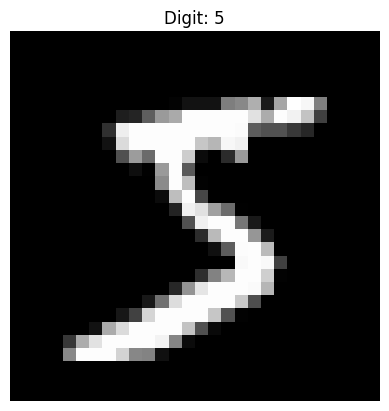

In [ ]:
# Get one image and its label
image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Image tensor:\n", image)
print("Label:", label)

# Display the image
plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Digit: {label}")
plt.axis("off")
plt.show()

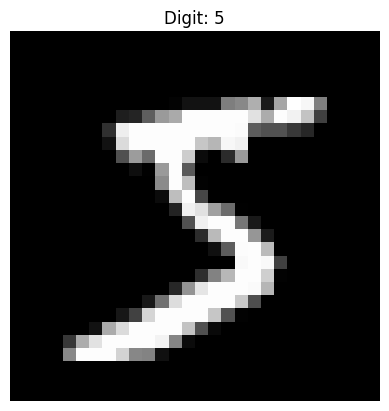

In [ ]:
image, label = train_dataset[0]

# Reverse normalization for display
image_to_display = image * 0.3081 + 0.1307

plt.imshow(image_to_display.squeeze(), cmap="gray")
plt.title(f"Digit: {label}")
plt.axis("off")
plt.show()

In [ ]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

# Inspect the first batch
images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)

Batch image shape: torch.Size([64, 1, 28, 28])
Batch label shape: torch.Size([64])


**Phase-2**

In [ ]:
import torch.nn as nn
import torch.nn.functional as F


class DigitCNN(nn.Module):
    def __init__(self):
        super().__init__()


        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=16,
            kernel_size=3
        )

        self.conv2 = nn.Conv2d(
            in_channels=16,
            out_channels=32,
            kernel_size=3
        )


        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)


        self.fc1 = nn.Linear(32 * 5 * 5, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))


        x = torch.flatten(x, start_dim=1)

        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x


In [ ]:
if __name__ == "__main__":
    model = DigitCNN()
    sample = torch.randn(1, 1, 28, 28)
    output = model(sample)

    print("Output shape:", output.shape)

Output shape: torch.Size([1, 10])


In [ ]:
from torch.optim import Adam



device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


model = DigitCNN().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = Adam(
    model.parameters(),
    lr=0.001
)

In [ ]:
# 5. Train the model
epochs = 5

for epoch in range(epochs):
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward propagation
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        total_loss += loss.item()
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    avg_loss = total_loss / len(train_loader)
    accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch + 1}/{epochs}] "
        f"Loss: {avg_loss:.4f} "
        f"Training Accuracy: {accuracy:.2f}%"
    )




Epoch [1/5] Loss: 0.2364 Training Accuracy: 93.04%
Epoch [2/5] Loss: 0.0645 Training Accuracy: 98.00%
Epoch [3/5] Loss: 0.0442 Training Accuracy: 98.65%
Epoch [4/5] Loss: 0.0348 Training Accuracy: 98.90%
Epoch [5/5] Loss: 0.0277 Training Accuracy: 99.14%


In [ ]:
# 6. Evaluate on test data
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

test_accuracy = 100 * correct / total

print(f"\nTest Accuracy: {test_accuracy:.2f}%")


# 7. Save trained weights
torch.save(model.state_dict(), "digit_cnn.pth")


Test Accuracy: 98.73%
